In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import networkx as nx

import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl
# import cmasher as cmr

ROOT = Path().cwd().resolve().parent
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src.inference import get_posterior_draws
from src.simulation import simple_kernel
from src.analysis import compute_complexity_score
from scipy.special import logit

/sfs/gpfs/tardis/home/pny2cw/projects/HETKER/heterogeneous-infection-kernels/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import fig_settings as fs

fs.set_colors()
fs.set_fonts()

# Data preprocessing

In [3]:
df = pd.read_parquet("../results/complexity/congress_omega_sweep/complexity_by_setting.parquet")
df.head()

,omega,complexity_mean,complexity_std,n_reps,mean_distance,trace_p_sigma,lw_reg_eff
0,0.000,1.981118,0.217743,10,115.673586,38.799557,0.007351
1,0.025,1.713477,0.381080,10,104.807145,38.590999,0.007968
2,0.050,1.486703,0.546867,10,96.189286,38.627407,0.008012
3,0.075,1.436610,0.612280,10,94.264825,38.626650,0.007805
4,0.100,1.275775,0.466708,10,87.824252,38.532464,0.007795


In [4]:
_kernels_lowomega = [
    np.load(f"../results/fits/congress_omega_sweep/model~np_rep~{rep}_omega~0.05.npz")["draws_mu"].mean(axis=0).flatten()
    for rep in range(10)
]
_kernels_highomega = [
    np.load(f"../results/fits/congress_omega_sweep/model~np_rep~{rep}_omega~0.45.npz")["draws_mu"].mean(axis=0).flatten()
    for rep in range(10)
]

mean_lowomega = np.array(_kernels_lowomega).mean(axis=0)
std_lowomega = np.array(_kernels_lowomega).std(axis=0)

mean_highomega = np.array(_kernels_highomega).mean(axis=0)
std_highomega = np.array(_kernels_highomega).std(axis=0)

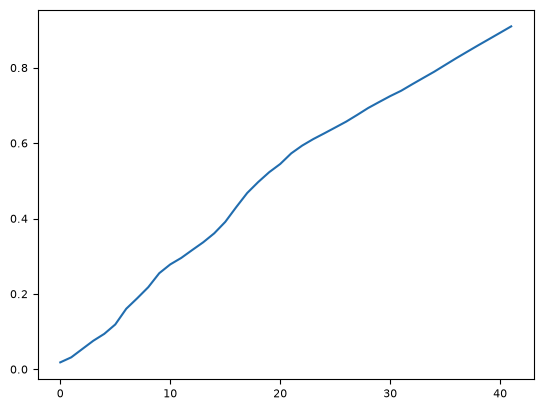

In [5]:
# opts: 1, 2?, 5?
# plt.plot(_kernels_lowomega[1], color=fs.palette[4])
plt.plot(_kernels_lowomega[2], color=fs.palette[4])
# plt.plot(_kernels_lowomega[5]) #, color=fs.palette[4])

In [6]:
def _hpdi(x, prob=0.5):
    """Narrowest interval containing `prob` of 1D samples."""
    x = np.sort(x)
    n = len(x)
    k = int(np.floor(prob * n))      # number of points inside the interval
    widths = x[k:] - x[:n - k]       # width of every candidate window
    i = np.argmin(widths)            # pick the narrowest
    return x[i], x[i + k]

def hpdi_bounds(X, prob=0.5):
    lower, upper = np.empty(X.shape[1]), np.empty(X.shape[1])
    for j in range(X.shape[1]):
        lower[j], upper[j] = _hpdi(X[:, j], prob=prob)
    return lower, upper

# Figure

In [7]:
_darkkernel = fs.palette[4]
_lightkernel = fs.palette[1]

_darkcomms = "#CD4862"
_lightcomms = "#722C6D"

In [8]:
kmax = len(mean_highomega)

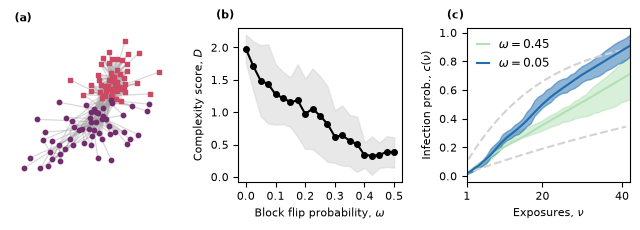

In [10]:
fig, axs = plt.subplots(
    1, 3,
    figsize=(8, 2),
)

plt.subplots_adjust(
    wspace=0.4
)

# --- Left panel - graph ----
axs_graph = axs[0]

axs_graph.spines['left'].set_visible(False)
axs_graph.spines['right'].set_visible(False)
axs_graph.spines['top'].set_visible(False)
axs_graph.spines['bottom'].set_visible(False)

axs_graph.patch.set_alpha(0.0)

G = nx.read_edgelist("../data/congress/processed/congress.edgelist")
pos = nx.spring_layout(G, seed=37)

_c1 = []
_c2 = []
with open("../data/congress/processed/communities.txt") as _fh:
    for node, line in enumerate(_fh.readlines()):
        if int(line.strip()) == 1:
            _c1.append(str(node))
        else:
            _c2.append(str(node))

nx.draw_networkx_nodes(
    G,
    pos=pos,
    ax=axs_graph,
    nodelist=_c1,
    # Node properties
    node_size=10,
    node_color=_darkcomms,
    node_shape="s"
)
nx.draw_networkx_nodes(
    G,
    pos=pos,
    ax=axs_graph,
    nodelist=_c2,
    # Node properties
    node_size=10,
    node_color=_lightcomms,
    node_shape="o"
)
nx.draw_networkx_edges(
    G,
    pos=pos,
    ax=axs_graph,
    # Edge properties
    width=0.9,
    alpha=0.40,
    edge_color='#a1a1a1'
)

axs_graph.text(
    -1, 1.3,
    "(a)",
    fontdict={"weight": "bold", "size": 8}
)


# --- Center panel - complexity ---
axs_complexity = axs[1]
axs_complexity.set_xlabel("Block flip probability, "+r"$\omega$")
axs_complexity.set_ylabel("Complexity score, "+r"$D$")

axs_complexity.set_xticks([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])

# Complexity as function of omega
axs_complexity.fill_between(
    x=df["omega"],
    y1=df["complexity_mean"]+df["complexity_std"],
    y2=df["complexity_mean"]-df["complexity_std"],
    color="lightgray",
    alpha=0.5
)
axs_complexity.plot(
    df["omega"],
    df["complexity_mean"],
    color="black",
    markersize=4,
    marker="o",
)

axs_complexity.text(
    -0.1, 2.45,
    "(b)",
    fontdict={"weight": "bold", "size": 8}
)

# --- Right panel ---
# Average kernels at particular omega
axs_kernel = axs[2]

axs_kernel.set_xlabel("Exposures, "+r"$\nu$")
axs_kernel.set_ylabel("Infection prob., "+r"$c(\nu)$")

axs_kernel.set_xticks([1,20,40])

axs_kernel.plot(simple_kernel(0.01, kmax), color="lightgray", linestyle="dashed")
axs_kernel.plot(simple_kernel(0.05, kmax), color="lightgray", linestyle="dashed")

NUS = range(1, len(mean_lowomega)+1)

highomega_lower, highomega_upper = hpdi_bounds(
    np.array([
        np.load(f"../results/fits/congress_omega_sweep/model~np_rep~{rep}_omega~0.45.npz")["draws_mu"][:, 0, :]
        for rep in range(10)
    ][2]),
    prob=0.9
)
axs_kernel.plot(
    NUS,
    mean_highomega,
    color=_lightkernel,
    label=r"$\omega = 0.45$"
)
axs_kernel.fill_between(
    x = NUS,
    y1 = highomega_lower,
    y2 = highomega_upper,
    color=_lightkernel,
    alpha=0.5
)

lowomega_lower, lowomega_upper = hpdi_bounds(
    np.array([
        np.load(f"../results/fits/congress_omega_sweep/model~np_rep~{rep}_omega~0.05.npz")["draws_mu"][:, 0, :]
        for rep in range(10)
    ][2]),
    prob=0.9
)
axs_kernel.plot(
    NUS,
    mean_lowomega,
    color=_darkkernel,
    label=r"$\omega = 0.05$"
)
axs_kernel.fill_between(
    x = NUS,
    y1 = lowomega_lower,
    y2 = lowomega_upper,
    color=_darkkernel,
    alpha=0.5
)

axs_kernel.set_xlim(1, kmax)

axs_kernel.legend(handlelength=1., fancybox=False, fontsize=8.5, frameon=False)

axs_kernel.text(
    -4, 1.10,
    "(c)",
    fontdict={"weight": "bold", "size": 8}
)

plt.savefig('../figs/figS2.svg', bbox_inches='tight')
plt.savefig('../figs/figS2.pdf', bbox_inches='tight')
plt.show()